# Extension - nested search and learning curves

**Question.** Is the tuning gain real, or did the search just find a lucky setting?

**Brief and report.** Parts E and F. Report Section 6 (Table 13) and Figure 11 (learning curves). Training rows only.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

`nested_search()` in `src/nested.py` repeats the whole search inside three outer folds. Each search is tuned on three inner folds, so the outer folds never influence the choice. It also draws learning curves: training and validation AP as the training set grows.

**How to read the output.**
- A nested gain close to the ordinary CV gain means the search did not just pick a lucky setting.
- In the learning curves, lines that meet mean bias: more data will not help.
- A lasting gap means variance: more data may help.

Nested search | outer fold: Logistic Regression fold 1: nested 0.625, default 0.625


Nested search | outer fold: Logistic Regression fold 2: nested 0.626, default 0.627


Nested search | outer fold: Logistic Regression fold 3: nested 0.631, default 0.631


Nested search | outer fold: Random Forest fold 1: nested 0.686, default 0.669


Nested search | outer fold: Random Forest fold 2: nested 0.679, default 0.661


Nested search | outer fold: Random Forest fold 3: nested 0.684, default 0.671


... (6 outputs left out)

,model,option,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio
0,Logistic Regression,nested,0.627,0.003,0.614,0.640,2.346e-05,3,0.5
1,Logistic Regression,default,0.628,0.003,0.615,0.640,2.028e-05,3,0.5
2,Random Forest,nested,0.683,0.004,0.668,0.698,2.593e-05,3,0.5
3,Random Forest,default,0.667,0.006,0.645,0.689,5.810e-05,3,0.5
4,Hist Gradient Boosting,nested,0.681,0.003,0.668,0.694,1.926e-05,3,0.5
5,Hist Gradient Boosting,default,0.673,0.003,0.662,0.684,1.489e-05,3,0.5


,model,option,reference,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm
0,Logistic Regression,nested,default,-2.916e-04,2.560e-04,-0.001,7.137e-04,0.338,3,0.5,0.338
1,Random Forest,nested,default,1.601e-02,2.892e-03,0.005,2.737e-02,0.026,3,0.5,0.052
2,Hist Gradient Boosting,nested,default,8.514e-03,6.468e-04,0.006,1.105e-02,0.005,3,0.5,0.014


,model,fraction,training_rows,train_ap,validation_ap,validation_sd
0,Logistic Regression,0.25,11645.667,0.630,0.622,6.050e-03
1,Logistic Regression,0.50,23292.000,0.630,0.625,2.494e-03
2,Logistic Regression,1.00,46584.667,0.631,0.627,3.126e-03
3,Random Forest,0.25,11645.667,0.991,0.652,3.110e-03
4,Random Forest,0.50,23292.000,0.986,0.670,4.703e-03
5,Random Forest,1.00,46584.667,0.979,0.683,4.330e-03
6,Hist Gradient Boosting,0.25,11645.667,0.885,0.658,9.715e-04
7,Hist Gradient Boosting,0.50,23292.000,0.835,0.672,4.026e-03
8,Hist Gradient Boosting,1.00,46584.667,0.801,0.683,2.537e-03


**reports/figures/fig_F_04_learning_curves.png**

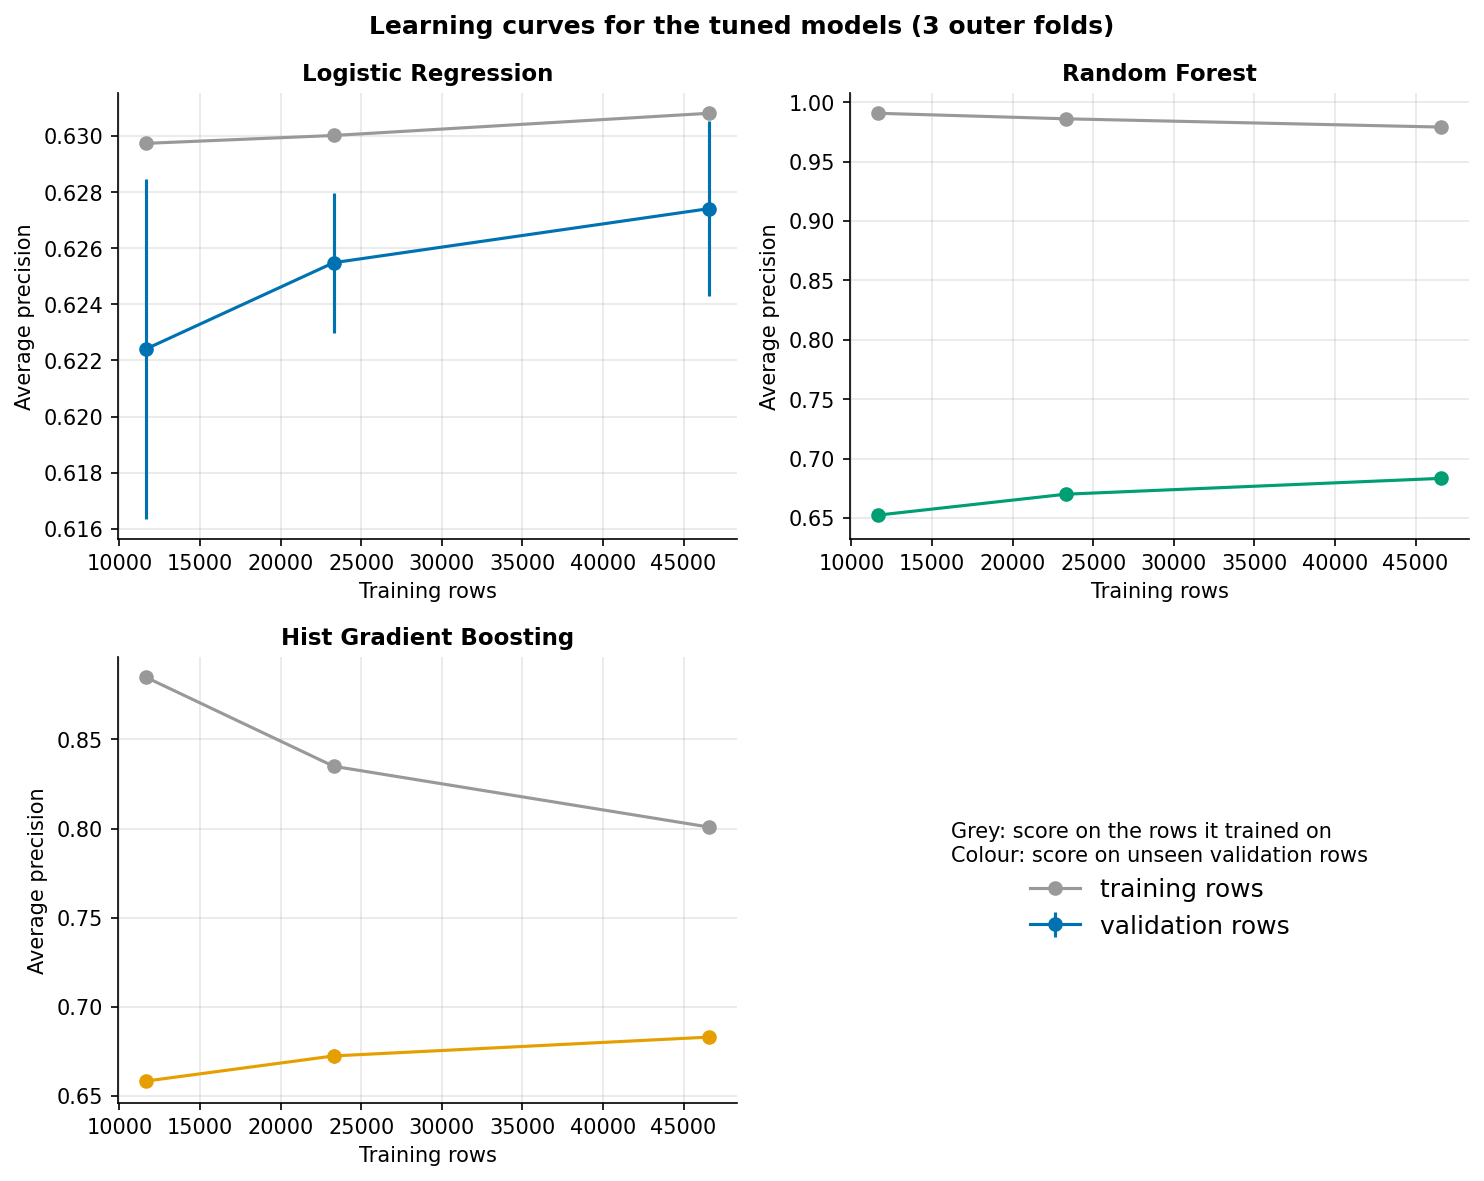

In [2]:
from src.nested import nested_search
summary, comparison, curves = nested_search()
display(summary)
display(comparison)
display(curves)
show('fig_F_04_learning_curves.png')